# Does trailer-week engagement predict opening-weekend collections?
**Reader:** Head of Distribution. **Decision:** Does trailer engagement deserve weight in an opening-weekend forecast used to plan initial promotion and screen discussions?

We screen 16 Hindi and regional releases from 2025. Engagement means **surviving top-level comments published during the first seven elapsed days after one selected official original-language trailer launched**. The target is **Friday–Sunday all-language India nett collections in INR crores**. All candidates are Friday releases.

This is a retrospective surviving-comment proxy. Current API views/likes cannot reconstruct their trailer-week values. Comment deletion, moderation and survival can depend on later events, so this is not an archived, real-time backtest. The notebook tests the stated proxy and records these limits explicitly.

Run `collect.py` first. No outcome or post-release view/like snapshot is used as a predictor. This is a regression study, not the sentiment/aspect-classification project.

In [1]:
%matplotlib inline
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_absolute_error, mean_squared_error
from joblib import dump

ROOT = Path.cwd().resolve()
if ROOT.name == "src":
    ROOT = ROOT.parent
elif (ROOT / "project/data").is_dir():
    ROOT = ROOT / "project"
DATA = ROOT / "data"
RAW, CLEAN, RESULTS = [DATA / part for part in ["raw", "clean", "results"]]
CLEAN.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["font.family"] = "DejaVu Sans"
log = []

def record(problem, rows, action, reason):
    log.append({"problem": problem, "rows_affected": int(rows), "action": action, "reason": reason})

def chart(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close("all")

def crores(value):
    text = str(value).replace(",", "").lower()
    number = re.search(r"\d+(?:\.\d+)?", text)
    if not number:
        return np.nan
    amount = float(number.group())
    if re.search(r"\b(cr|crore)\b", text):
        return amount
    if re.search(r"\b(l|lakh|lakhs)\b", text):
        return amount / 100
    return amount / 10000000

assert crores("₹12.5 Cr") == 12.5
assert crores("1,25,00,000") == 1.25
assert crores("₹25 L") == 0.25

## Sources and joins
YouTube supplies JSON metadata and comment text. Wikipedia supplies HTML film context. Sacnilk supplies the public all-language India-net daily table; estimates may differ from other trackers. Stanford's IMDb corpus is used only by the separate required Spark exercise.

Film IDs are the join key. Trailer selection is recorded in `films.csv`: original-language full theatrical trailer, official producer/studio upload preferred, no teasers, OTT or success trailers. Different channel audiences and duplicated official uploads remain confounders. The current counter snapshots are retained for provenance only.

In [2]:
films = pd.read_csv(DATA / "films.csv", dtype={"film_id": "string", "video_id": "string"})
films["release_date"] = pd.to_datetime(films["release_date"])
films["release_at"] = films["release_date"].dt.tz_localize("Asia/Kolkata").dt.tz_convert("UTC")
video_rows, comment_frames, daily_rows, metadata, coverage, sources = [], [], [], [], [], []

for film in films.to_dict("records"):
    folder = RAW / film["film_id"]
    video = pd.json_normalize(json.loads((folder / "video.json").read_text())["items"])
    video["film_id"] = film["film_id"]
    video_rows.append(video)
    state_file = folder / "collection_state.json"
    state = json.loads(state_file.read_text()) if state_file.exists() else {"complete": False, "pages": 0}
    coverage.append({"film_id": film["film_id"], "history_complete": state["complete"], "pages": state["pages"],
                     "collected_at": state.get("collected_at")})
    if (folder / "comments.jsonl").exists():
        frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)
        frame["film_id"] = film["film_id"]
        comment_frames.append(frame)
    wiki = BeautifulSoup((folder / "wikipedia.html").read_text(), "html.parser")
    infobox = wiki.select_one("table.infobox")
    for reference in infobox.select("sup"):
        reference.decompose()
    fields = {row.th.get_text(" ", strip=True).lower(): row.td.get_text(" ", strip=True)
              for row in infobox.select("tr") if row.th and row.td}
    metadata.append({"film_id": film["film_id"], "runtime_raw": fields.get("running time"),
                     "budget_raw": fields.get("budget"), "wiki_language": fields.get("language")})
    box = BeautifulSoup((folder / "box_office.html").read_text(), "html.parser")
    tables = [table for table in box.select("table") if [cell.get_text(" ", strip=True) for cell in table.select("tr")[0].find_all(["th", "td"])][:3] == ["Day", "India net", "India gross"]]
    assert len(tables) == 1, f"Check all-language India net table: {film['title']}"
    for row in tables[0].select("tr"):
        cells_ = row.find_all("td")
        if not cells_:
            continue
        day = re.match(r"Day\s+(\d+)\b", cells_[0].get_text(" ", strip=True))
        if day:
            daily_rows.append({"film_id": film["film_id"], "day": int(day[1]),
                               "date": film["release_date"] + pd.Timedelta(days=int(day[1]) - 1),
                               "india_net_raw": cells_[1].get_text(" ", strip=True),
                               "source_url": film["box_office_url"]})
    accessed = state.get("collected_at") or datetime.fromtimestamp((folder / "box_office.html").stat().st_mtime, timezone.utc).isoformat()
    for source, url, format_, method, terms in [
        ("YouTube Data API v3", "https://www.youtube.com/watch?v=" + film["video_id"], "JSON + free text", "videos.list and paginated newest-first commentThreads.list", "YouTube API Terms and Developer Policies; no author fields saved"),
        ("Wikipedia", film["wikipedia_url"], "HTML", "Public infobox parsed with BeautifulSoup", "Wikimedia Terms of Use; attribution required"),
        ("Sacnilk", film["box_office_url"], "HTML table", "Public all-language India nett table, not premium tracked data", "Public /movie pages permitted by robots.txt; current terms URL returned 404; figures attributed; raw page redistribution excluded")]:
        sources.append({"film_id": film["film_id"], "source": source, "url": url, "accessed_at": accessed,
                        "format": format_, "method": method, "terms": terms})

films = films.merge(pd.DataFrame(metadata), on="film_id", validate="one_to_one")
videos = pd.concat(video_rows, ignore_index=True).rename(columns={"id": "video_id", "snippet.publishedAt": "trailer_at",
    "snippet.title": "video_title", "statistics.viewCount": "current_views", "statistics.likeCount": "current_likes"})
videos = videos[["film_id", "video_id", "video_title", "trailer_at", "current_views", "current_likes"]]
videos["trailer_at"] = pd.to_datetime(videos["trailer_at"], utc=True)
for column in ["current_views", "current_likes"]:
    videos[column] = pd.to_numeric(videos[column], errors="coerce").astype("Int64")
comments = pd.concat(comment_frames, ignore_index=True)
daily = pd.DataFrame(daily_rows)
coverage = pd.DataFrame(coverage)
films["runtime_minutes"] = pd.to_numeric(films["runtime_raw"].str.extract(r"(\d+)", expand=False), errors="coerce")
display(films[["title", "language", "release_date", "budget_raw"]])

/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)
/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


... (3 outputs left out)

/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/2469445795.py:16: Pandas4Warning: The 'convert_dates' keyword in read_json is deprecated and will be removed in a future version. Pass dtype=False to disable type conversion, or parse date columns with pd.to_datetime after reading.
  frame = pd.read_json(folder / "comments.jsonl", lines=True, convert_dates=False)


,title,language,release_date,budget_raw
0,Chhaava,Hindi,2025-02-14,₹ 90–130 crore
1,Housefull 5,Hindi,2025-06-06,₹225 crore
2,Sitaare Zameen Par,Hindi,2025-06-20,₹122 crore
3,Saiyaara,Hindi,2025-07-18,₹45 crore
4,Dhadak 2,Hindi,2025-08-01,NaN
5,Jolly LLB 3,Hindi,2025-09-19,₹120 crore
6,Dhurandhar,Hindi,2025-12-05,₹ 250–255 crore (combined with part 2 )
7,Bhool Chuk Maaf,Hindi,2025-05-23,₹ 50 crore
8,Dragon,Tamil,2025-02-21,₹ 37 crore
9,Madharaasi,Tamil,2025-09-05,₹ 170 crore


## Clean the event counts and collections
For engagement, the unit is a comment event, so identical comments from different IDs remain in the primary count. Duplicate IDs from resumed collection are removed. Text cleaning and repeated-text shares are separate diagnostics; no English-only filter is applied to multilingual comment volume.

Missing collections remain missing. The target requires all three days, not a partial sum. We use India **nett**, never worldwide gross or an extended weekend. Budgets are retained as source text and excluded because ranges, missing values and production-cost definitions are inconsistent.

In [3]:
record("Film titles and legacy source URLs differ", len(films), "Join on manually verified canonical film IDs", "Madharaasi/Madharasi and Game Changer/RC15 refer to the same respective films")
raw_count = len(comments)
duplicates = comments.duplicated("comment_id")
record("Repeated comment IDs across collection pages", duplicates.sum(), "Keep one row per comment ID", "The unit is a posted comment, not copied text")
comments = comments.drop_duplicates("comment_id").copy()
comments["published_at"] = pd.to_datetime(comments["published_at"], utc=True)
comments["updated_at"] = pd.to_datetime(comments["updated_at"], utc=True)
comments["text_clean"] = (comments["text"].fillna("").str.replace(r"<[^>]+>|https?://\S+|@[\w.-]+", " ", regex=True)
                           .str.replace(r"\s+", " ", regex=True).str.strip())
comments = comments.merge(videos[["film_id", "trailer_at"]], on="film_id", validate="many_to_one")
comments["days_from_trailer"] = (comments["published_at"] - comments["trailer_at"]).dt.total_seconds() / 86400
comments["in_trailer_week"] = comments["days_from_trailer"].between(0, 7, inclusive="left")
comments["word_count"] = comments["text_clean"].str.split().str.len()
record("HTML, URLs, account mentions and whitespace in text", len(comments), "Strip noise for text diagnostics", "Do not change the timestamped event count")
record("Repeated text with different IDs", comments.duplicated(["film_id", "text_clean"]).sum(), "Retain events; report repetition separately", "Repeated slogans can be genuine or promotional; users are not identified")
record("Dates and counts encoded as strings", len(comments) + len(videos), "Cast timestamps to UTC and counters to nullable integers", "Make elapsed-day windows explicit")

daily["india_net_cr"] = daily["india_net_raw"].map(crores)
assert not daily.duplicated(["film_id", "day"]).any()
record("Collections use crore, lakh or Indian comma grouping", len(daily), "Convert to INR crores", "Use one outcome unit")
record("Missing daily collection amounts", daily["india_net_cr"].isna().sum(), "Keep missing; reject incomplete target windows", "Missing is not zero")
record("Inconsistent budget values", len(films), "Preserve text and exclude budgets from predictors", "Do not invent midpoints or silently mix cost definitions")

week = comments[comments["in_trailer_week"]]
counts = week.groupby("film_id").size().rename("trailer_week_comments")
first_day = week[week["days_from_trailer"] < 1].groupby("film_id").size().rename("first_day_comments")
opening_days = daily[daily["day"].between(1, 3)]
opening = opening_days.groupby("film_id").agg(target_days=("india_net_cr", "count"), opening_weekend_cr=("india_net_cr", lambda values: values.sum(min_count=3)))
features = (films.merge(videos, on=["film_id", "video_id"], validate="one_to_one").merge(coverage, on="film_id", validate="one_to_one")
            .merge(counts, on="film_id", how="left").merge(first_day, on="film_id", how="left").merge(opening, on="film_id", how="left"))
complete = features["history_complete"]
features.loc[complete, ["trailer_week_comments", "first_day_comments"]] = features.loc[complete, ["trailer_week_comments", "first_day_comments"]].fillna(0)
features["trailer_week_end"] = features["trailer_at"] + pd.Timedelta(days=7)
features["lead_days"] = (features["release_at"] - features["trailer_at"]).dt.total_seconds() / 86400
features["reason"] = ""
for failed, reason in [
    (features["release_date"].dt.dayofweek.ne(4), "Not a Friday release"),
    (features["trailer_week_end"] > features["release_at"], "Trailer week overlaps theatrical release"),
    (~complete, "Comment history incomplete or not collected"),
    (features["target_days"].ne(3) | features["opening_weekend_cr"].isna(), "Missing three-day India nett target")]:
    features.loc[failed, "reason"] += reason + "; "
features["eligible"] = features["reason"].eq("")
features["group"] = np.where(features["language"].eq("Hindi"), "Hindi", "Regional")
features["hindi"] = features["language"].eq("Hindi").astype(int)
features["log_comments"] = np.log1p(features["trailer_week_comments"])
for reason in ["Trailer week overlaps theatrical release", "Comment history incomplete or not collected", "Missing three-day India nett target"]:
    record(reason, features["reason"].str.contains(reason, regex=False).sum(), "Exclude from prediction", "Do not turn unavailable or post-release information into a pre-release feature")
record("Current views and likes measured after release", len(features), "Keep as provenance; exclude from predictors", "Avoid temporal leakage")
cohort = features[features["eligible"]].sort_values(["release_date", "film_id"]).reset_index(drop=True)
assert len(cohort) >= 8 and cohort["group"].nunique() == 2
assert (cohort["trailer_week_end"] <= cohort["release_at"]).all()
assert cohort["trailer_week_comments"].notna().all()
features.to_csv(RESULTS / "cohort_audit.csv", index=False)
cohort.to_csv(CLEAN / "model_data.csv", index=False)
display(features[["title", "group", "trailer_week_comments", "opening_weekend_cr", "eligible", "reason"]])

/var/folders/z7/k8gvl0012rz_j3j2m5r2vwt80000gn/T/ipykernel_6566/3342228678.py:37: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  (features["release_date"].dt.dayofweek.ne(4), "Not a Friday release"),


,title,group,trailer_week_comments,opening_weekend_cr,eligible,reason
0,Chhaava,Hindi,72664.0,116.50,True,
1,Housefull 5,Hindi,28612.0,87.50,True,
2,Sitaare Zameen Par,Hindi,41383.0,58.15,True,
3,Saiyaara,Hindi,9974.0,83.25,True,
4,Dhadak 2,Hindi,4224.0,11.40,True,
5,Jolly LLB 3,Hindi,6715.0,53.50,True,
6,Dhurandhar,Hindi,28063.0,103.00,True,
7,Bhool Chuk Maaf,Hindi,2325.0,28.00,True,
8,Dragon,Regional,7439.0,30.05,True,
9,Madharaasi,Regional,41.0,37.15,True,


## EDA: association is different from prediction
Each observation is one film. Hundreds of thousands of comments do not create hundreds of thousands of independent box-office observations. We report the actual eligible film count, language mix and release lead times.

The scatter and z-score chart combine YouTube and Sacnilk. Z-scores put different units on a common display but do not control for budgets, star power, marketing, paid views, channel size or screen availability.

,films,median_comments,median_opening_cr
group,,,
Hindi,8,19018.5,70.70
Regional,7,4503.0,30.75


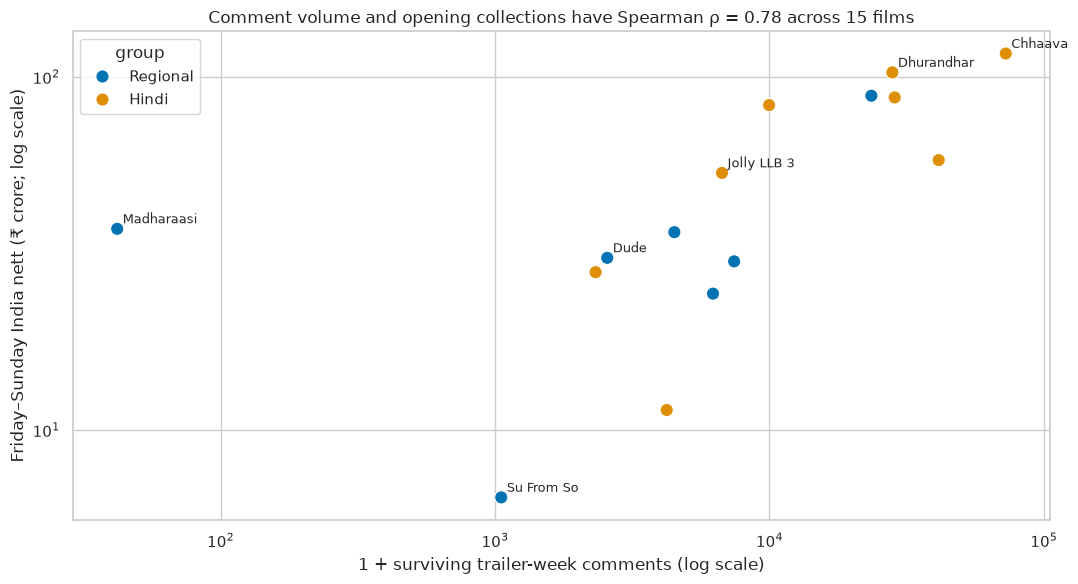

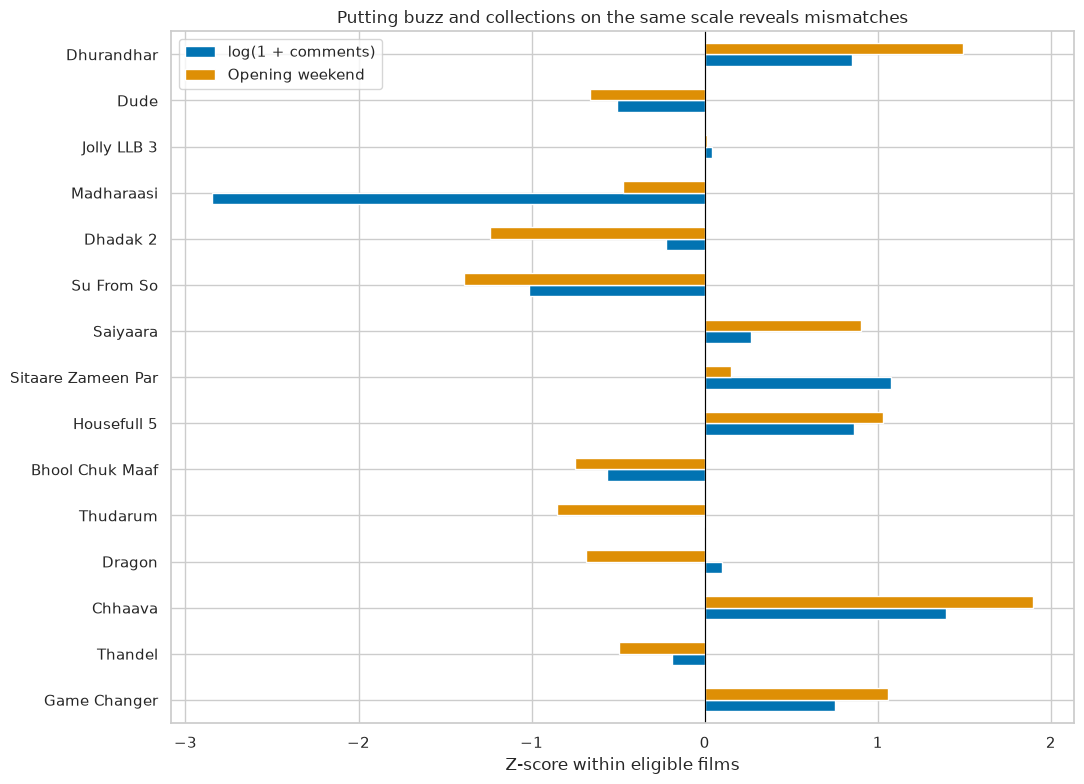

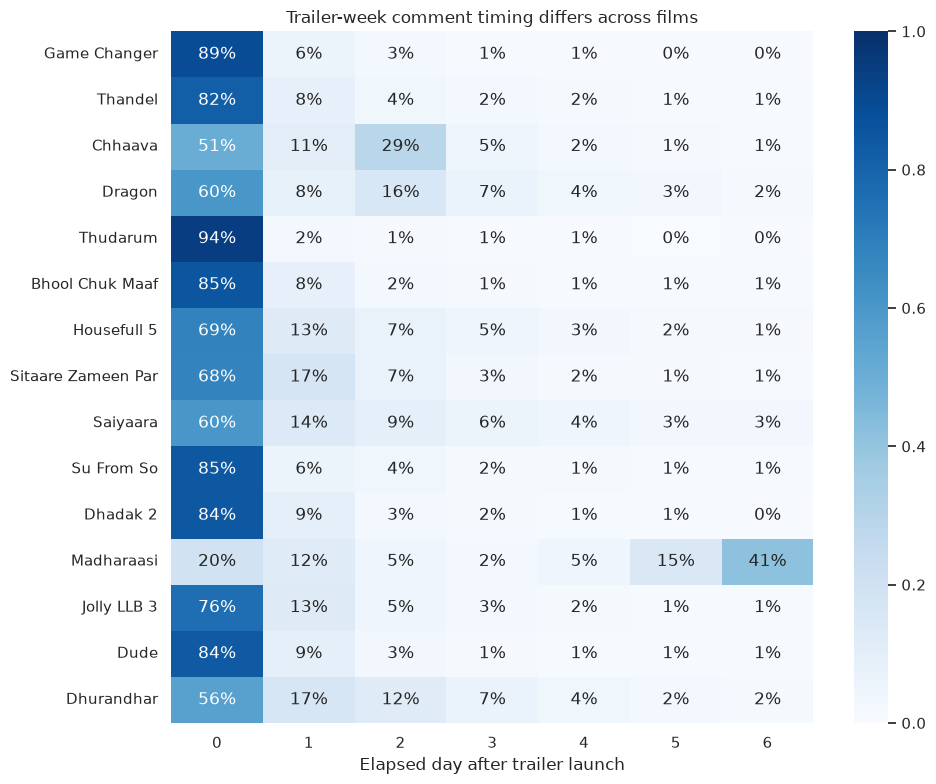

In [4]:
display(cohort.groupby("group").agg(films=("film_id", "size"), median_comments=("trailer_week_comments", "median"), median_opening_cr=("opening_weekend_cr", "median")))
rho = cohort[["trailer_week_comments", "opening_weekend_cr"]].corr(method="spearman").iloc[0, 1]
plt.figure(figsize=(11, 6))
sns.scatterplot(data=cohort.assign(comments_plus_one=cohort["trailer_week_comments"] + 1), x="comments_plus_one", y="opening_weekend_cr", hue="group", s=90)
label_rows = pd.concat([cohort.tail(4), cohort.nlargest(1, "opening_weekend_cr"), cohort.nsmallest(1, "opening_weekend_cr")]).drop_duplicates("film_id")
for row in label_rows.itertuples():
    plt.annotate(row.title, (row.trailer_week_comments + 1, row.opening_weekend_cr), xytext=(4, 4), textcoords="offset points", fontsize=9)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("1 + surviving trailer-week comments (log scale)")
plt.ylabel("Friday–Sunday India nett (₹ crore; log scale)")
plt.title(f"Comment volume and opening collections have Spearman ρ = {rho:.2f} across {len(cohort)} films")
chart("01_comments_vs_opening")

normalised = pd.DataFrame(StandardScaler().fit_transform(cohort[["log_comments", "opening_weekend_cr"]]),
                          index=cohort["title"], columns=["log(1 + comments)", "Opening weekend"])
normalised.plot.barh(figsize=(11, 8))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Z-score within eligible films")
plt.ylabel("")
plt.title("Putting buzz and collections on the same scale reveals mismatches")
chart("02_normalised_comparison")
normalised.to_csv(RESULTS / "normalised_values.csv")

eligible_week = week[week["film_id"].isin(cohort["film_id"])].copy()
eligible_week["day"] = np.floor(eligible_week["days_from_trailer"]).astype(int)
velocity = eligible_week.groupby(["film_id", "day"]).size().unstack(fill_value=0).reindex(index=cohort["film_id"], columns=range(7), fill_value=0)
share = velocity.div(velocity.sum(axis=1).replace(0, np.nan), axis=0)
share.index = cohort["title"]
plt.figure(figsize=(10, 8))
sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1)
plt.title("Trailer-week comment timing differs across films")
plt.xlabel("Elapsed day after trailer launch")
plt.ylabel("")
chart("03_trailer_week_velocity")
velocity.to_csv(RESULTS / "trailer_week_daily_comments.csv")

## Prediction design: a small forward holdout
The **last four films by release date** form the fixed test set; earlier films form training. This split is chosen before comparing scores. Same-day releases stay together. All scalers and coefficients are fitted only on training rows.

We compare a training-median baseline, a Hindi/regional-only model, comments alone, and the pre-specified primary model: Hindi/regional + comments. The main question is whether adding comments improves over the language-only baseline. A group indicator controls only this broad grouping, not other confounders.

Ridge regression uses a fixed penalty of 1 rather than tuning against the tiny test set. We model `log(1 + collections)` to reduce domination by very large openings, and convert predictions back to crores. `log(1 + comments)` handles skew and zero counts. Negative back-transformed predictions are clipped to zero. No post-release counters, opening-day collections or target-derived ratios enter features.

,title,release_date,split
0,Game Changer,2025-01-10,train
1,Thandel,2025-02-07,train
2,Chhaava,2025-02-14,train
3,Dragon,2025-02-21,train
4,Thudarum,2025-04-25,train
5,Bhool Chuk Maaf,2025-05-23,train
6,Housefull 5,2025-06-06,train
7,Sitaare Zameen Par,2025-06-20,train
8,Saiyaara,2025-07-18,train
9,Su From So,2025-07-25,train


,title,release_date,split
11,Madharaasi,2025-09-05,test
12,Jolly LLB 3,2025-09-19,test
13,Dude,2025-10-17,test
14,Dhurandhar,2025-12-05,test


,model,train_films,test_films,mae_cr,rmse_cr
0,Training median,11,4,22.550000,34.526602
1,Language only,11,4,17.162410,27.264842
2,Comments only,11,4,25.367301,27.045196
3,Language + comments,11,4,24.782793,26.390536


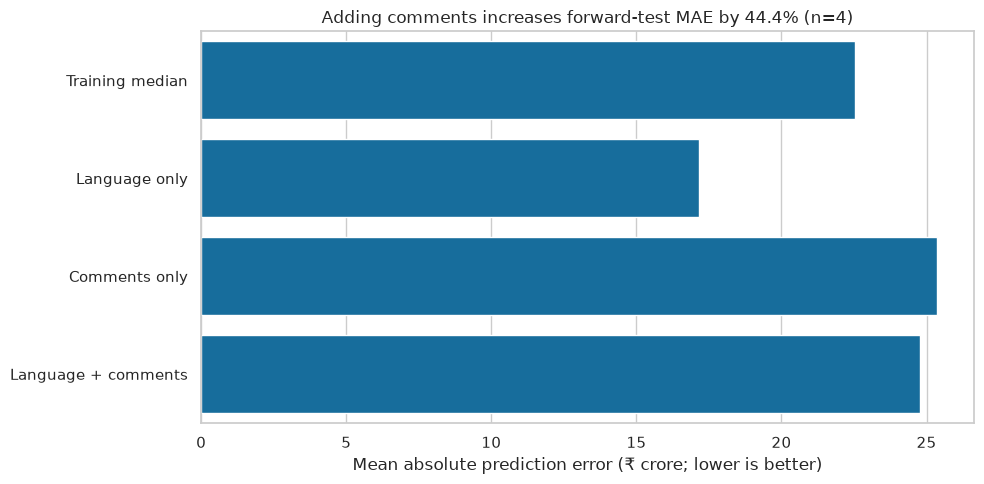

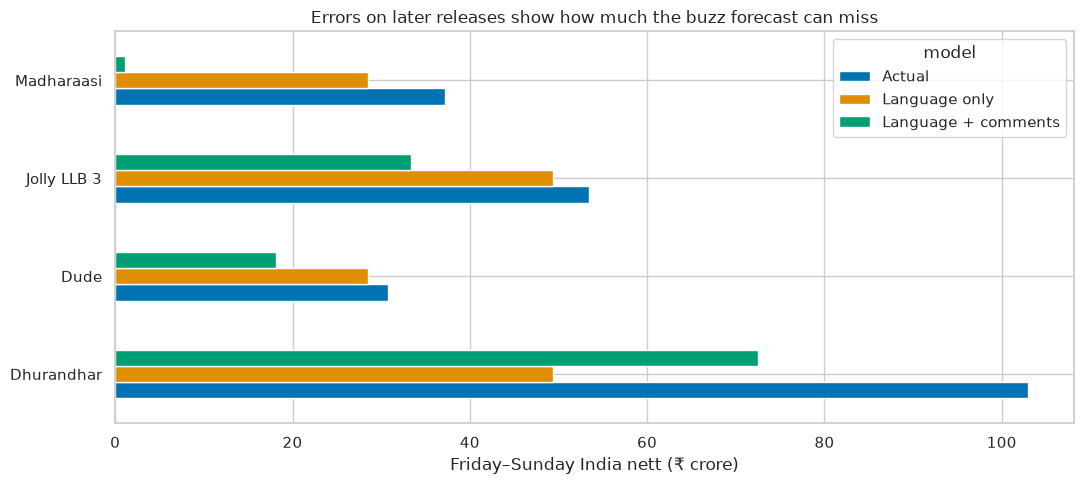

In [5]:
cutoff = cohort.iloc[-4]["release_date"]
train = cohort[cohort["release_date"] < cutoff]
test = cohort[cohort["release_date"] >= cutoff].copy()
test["outside_training_comment_range"] = ~test["trailer_week_comments"].between(train["trailer_week_comments"].min(), train["trailer_week_comments"].max())
models = {"Training median": [], "Language only": ["hindi"], "Comments only": ["log_comments"], "Language + comments": ["hindi", "log_comments"]}

def predict(training, testing, columns):
    if not columns:
        return np.repeat(training["opening_weekend_cr"].median(), len(testing))
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(training[columns], np.log1p(training["opening_weekend_cr"]))
    return np.maximum(np.expm1(model.predict(testing[columns])), 0)

predictions, scores = [], []
for name, columns in models.items():
    estimated = predict(train, test, columns)
    scores.append({"model": name, "train_films": len(train), "test_films": len(test),
                   "mae_cr": mean_absolute_error(test["opening_weekend_cr"], estimated),
                   "rmse_cr": np.sqrt(mean_squared_error(test["opening_weekend_cr"], estimated))})
    predictions.append(test[["film_id", "title", "group", "release_date", "opening_weekend_cr", "outside_training_comment_range"]].assign(model=name, predicted_cr=estimated))
scores = pd.DataFrame(scores)
predictions = pd.concat(predictions, ignore_index=True)
scores.to_csv(RESULTS / "holdout_metrics.csv", index=False)
predictions.to_csv(RESULTS / "holdout_predictions.csv", index=False)
display(train[["title", "release_date"]].assign(split="train"))
display(test[["title", "release_date"]].assign(split="test"))
display(scores)

base_mae = scores.set_index("model").loc["Language only", "mae_cr"]
buzz_mae = scores.set_index("model").loc["Language + comments", "mae_cr"]
improvement = 100 * (base_mae - buzz_mae) / base_mae
plt.figure(figsize=(10, 5))
sns.barplot(data=scores, x="mae_cr", y="model")
plt.xlabel("Mean absolute prediction error (₹ crore; lower is better)")
plt.ylabel("")
plt.title(f"Adding comments {'reduces' if improvement >= 0 else 'increases'} forward-test MAE by {abs(improvement):.1f}% (n={len(test)})")
chart("04_holdout_model_errors")

comparison = predictions.pivot(index="title", columns="model", values="predicted_cr")
comparison["Actual"] = test.set_index("title")["opening_weekend_cr"]
comparison[["Actual", "Language only", "Language + comments"]].plot.barh(figsize=(11, 5))
plt.xlabel("Friday–Sunday India nett (₹ crore)")
plt.ylabel("")
plt.title("Errors on later releases show how much the buzz forecast can miss")
chart("05_actual_vs_predicted")

## Sensitivity: do conclusions depend on four test films?
Leave-one-film-out evaluation gives every film a held-out prediction. It is a sensitivity check, **not a forward forecast**, because training can contain films released later than the held-out film. A second diagnostic removes the largest-opening film before re-running leave-one-out, to reveal dependence on one blockbuster.

These are fixed comparisons, not hyperparameter searches. We do not pick a winning model from the sensitivity results and then claim an untouched test result for it.

In [6]:
loo_rows = []
for scenario, sample in [("All eligible films", cohort), ("Without largest opening", cohort.drop(cohort["opening_weekend_cr"].idxmax()).reset_index(drop=True))]:
    for name, columns in models.items():
        actual, estimated = [], []
        for training_index, testing_index in LeaveOneOut().split(sample):
            training, testing = sample.iloc[training_index], sample.iloc[testing_index]
            actual.extend(testing["opening_weekend_cr"])
            estimated.extend(predict(training, testing, columns))
        loo_rows.append({"scenario": scenario, "model": name, "films": len(sample),
                         "mae_cr": mean_absolute_error(actual, estimated),
                         "rmse_cr": np.sqrt(mean_squared_error(actual, estimated))})
loo = pd.DataFrame(loo_rows)
loo.to_csv(RESULTS / "leave_one_out_sensitivity.csv", index=False)
display(loo)

primary = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(train[models["Language + comments"]], np.log1p(train["opening_weekend_cr"]))
dump(primary, RESULTS / "forecast_model.joblib")
weights = pd.DataFrame({"feature": models["Language + comments"], "standardised_log_target_weight": primary[1].coef_})
weights.to_csv(RESULTS / "model_coefficients.csv", index=False)
display(weights)

answer = (f"Across {len(cohort)} eligible films, surviving trailer-week comment volume has Spearman correlation {rho:.2f} with opening-weekend India nett. "
          f"On the {len(test)} later-release test films, adding comments to the Hindi/regional baseline {'reduced' if improvement >= 0 else 'increased'} MAE by {abs(improvement):.1f}%, from ₹{base_mae:.2f} crore to ₹{buzz_mae:.2f} crore. "
          "The sample and retrospective surviving-comment measure are too limited to establish a reliable general forecasting rule.")
action = ("Use comment volume only as an experimental supporting forecast input, alongside local advance bookings, screens and comparable releases; do not allocate screens from it alone."
          if improvement > 0 else "Do not give comment volume weight in next Friday's allocation or promotion budget on this evidence; keep the baseline and collect a larger prospective sample.")
rmse = scores.set_index("model")["rmse_cr"]
answer += (f" RMSE changes from INR {rmse['Language only']:.2f} crore to INR {rmse['Language + comments']:.2f} crore, "
           "and leave-one-out errors differ from the forward holdout: the conclusion depends on the metric and evaluation split.")
(RESULTS / "findings.txt").write_text(answer + "\n\nRecommendation: " + action + "\n")
display(Markdown(answer + "\n\n**Recommendation:** " + action))

,scenario,model,films,mae_cr,rmse_cr
0,All eligible films,Training median,15,32.723333,39.066232
1,All eligible films,Language only,15,26.634340,35.604941
2,All eligible films,Comments only,15,23.733831,28.312017
3,All eligible films,Language + comments,15,24.510921,29.546045
4,Without largest opening,Training median,14,24.950000,32.395883
5,Without largest opening,Language only,14,24.988741,33.066855
6,Without largest opening,Comments only,14,22.506250,27.967372
7,Without largest opening,Language + comments,14,23.769358,29.541393


,feature,standardised_log_target_weight
0,hindi,0.036465
1,log_comments,0.652491


Across 15 eligible films, surviving trailer-week comment volume has Spearman correlation 0.78 with opening-weekend India nett. On the 4 later-release test films, adding comments to the Hindi/regional baseline increased MAE by 44.4%, from ₹17.16 crore to ₹24.78 crore. The sample and retrospective surviving-comment measure are too limited to establish a reliable general forecasting rule. RMSE changes from INR 27.26 crore to INR 26.39 crore, and leave-one-out errors differ from the forward holdout: the conclusion depends on the metric and evaluation split.

**Recommendation:** Do not give comment volume weight in next Friday's allocation or promotion budget on this evidence; keep the baseline and collect a larger prospective sample.

## Audit outputs and reproducibility
Every exclusion is visible in the cohort audit. The cleaning log records actual actions. Source URLs, access times, measurement types, the three-V profile and raw checksums are saved with the results.

The project contains `schema.sql`, `queries.sql`, `load_mysql.py` and a separate `spark_job.py`. SQL and Spark run downstream of notebook cleaning; neither creates additional independent films for the forecasting model. IMDb benchmark rows stay in their own Spark group.

In [7]:
imdb = pd.read_csv(DATA / "imdb.csv.gz")
imdb.groupby(["split", "label"]).sample(50, random_state=42).to_csv(DATA / "imdb_sample.csv", index=False)
films.to_csv(CLEAN / "films.csv", index=False)
videos.to_csv(CLEAN / "videos.csv", index=False)
daily.to_csv(CLEAN / "daily_collections.csv", index=False)
comments.drop(columns="text").to_csv(CLEAN / "comments.csv.gz", index=False, compression="gzip")
pd.DataFrame(log).to_csv(RESULTS / "cleaning_log.csv", index=False)
coverage.to_csv(RESULTS / "collection_coverage.csv", index=False)

sources.append({"film_id": "benchmark_only", "source": "Stanford IMDb", "url": "https://ai.stanford.edu/~amaas/data/sentiment/",
                "accessed_at": datetime.fromtimestamp((RAW / "aclImdb_v1.tar.gz").stat().st_mtime, timezone.utc).isoformat(),
                "format": "TAR.GZ containing labelled TXT", "method": "Official archive; 50000 labelled rows for Spark only",
                "terms": "Cite Maas et al. 2011 and see raw/imdb_README.txt"})
pd.DataFrame(sources).to_csv(RESULTS / "source_register.csv", index=False)
nominal = {"film_id", "title", "language", "wikipedia_url", "video_id", "channel", "box_office_url", "selection_reason", "budget_raw", "wiki_language", "video_title", "comment_id", "text_clean", "source_url", "reason", "group"}
inventory = []
for name, frame, shape in [("films", films, "structured configuration and HTML extraction"), ("videos", videos, "semi-structured JSON flattened"), ("comments", comments.drop(columns="text"), "semi-structured JSON flattened"), ("daily_collections", daily, "structured HTML table"), ("model_data", cohort, "structured derived features")]:
    for column in frame.columns:
        kind = "nominal" if column in nominal or pd.api.types.is_bool_dtype(frame[column]) else "continuous"
        if column in {"day", "word_count", "current_views", "current_likes", "trailer_week_comments", "first_day_comments", "target_days", "pages"}:
            kind = "discrete"
        if column == "hindi":
            kind = "nominal (binary group)"
        if column in {"runtime_raw", "budget_raw", "india_net_raw"}:
            kind = "continuous (encoded as source text)"
        inventory.append({"table": name, "field": column, "measurement_type": kind,
                          "representation": "unstructured" if column == "text_clean" else shape, "dtype": str(frame[column].dtype)})
pd.DataFrame(inventory).to_csv(RESULTS / "data_inventory.csv", index=False)
raw_files = [path for path in RAW.rglob("*") if path.is_file()]
profile = {"candidate_films": len(features), "eligible_films": len(cohort), "raw_comment_rows": raw_count,
           "imdb_labelled_rows": len(imdb), "unique_comment_events": len(comments), "trailer_week_comment_events": len(eligible_week),
           "raw_mb": round(sum(path.stat().st_size for path in raw_files) / 1e6, 2),
           "first_day_comments_per_hour": cohort.set_index("film_id")["first_day_comments"].div(24).to_dict(),
           "formats": ["JSON", "HTML tables", "free text", "TXT in TAR.GZ", "CSV"],
           "dominant_v": "Variety", "secondary_v": "Velocity",
           "tools": "pandas for local joins and forecasting; API pagination to reach the historical window; Spark for the required 50000+ row text exercise",
           "limits": "Surviving top-level comments only; not unique people, historical views, replies or deleted comments"}
(RESULTS / "v_profile.json").write_text(json.dumps(profile, indent=2))
(RESULTS / "raw_checksums.json").write_text(json.dumps({str(path.relative_to(DATA)): hashlib.sha256(path.read_bytes()).hexdigest() for path in raw_files}, indent=2))
examples = pd.DataFrame({"raw_amount": ["₹12.5 Cr", "1,25,00,000", "₹25 L"]})
examples["pandas_crores"] = examples["raw_amount"].map(crores)
examples["spreadsheet_result_pending"] = ""
examples.to_csv(RESULTS / "spreadsheet_check.csv", index=False)
display(pd.DataFrame(log))
display(pd.Series(profile).to_frame("value"))

,problem,rows_affected,action,reason
0,Film titles and legacy source URLs differ,16,Join on manually verified canonical film IDs,Madharaasi/Madharasi and Game Changer/RC15 ref...
1,Repeated comment IDs across collection pages,3,Keep one row per comment ID,"The unit is a posted comment, not copied text"
2,"HTML, URLs, account mentions and whitespace in...",305444,Strip noise for text diagnostics,Do not change the timestamped event count
3,Repeated text with different IDs,42843,Retain events; report repetition separately,Repeated slogans can be genuine or promotional...
4,Dates and counts encoded as strings,305460,Cast timestamps to UTC and counters to nullabl...,Make elapsed-day windows explicit
5,"Collections use crore, lakh or Indian comma gr...",992,Convert to INR crores,Use one outcome unit
6,Missing daily collection amounts,161,Keep missing; reject incomplete target windows,Missing is not zero
7,Inconsistent budget values,16,Preserve text and exclude budgets from predictors,Do not invent midpoints or silently mix cost d...
8,Trailer week overlaps theatrical release,1,Exclude from prediction,Do not turn unavailable or post-release inform...
9,Comment history incomplete or not collected,1,Exclude from prediction,Do not turn unavailable or post-release inform...


,value
candidate_films,16
eligible_films,15
raw_comment_rows,305447
imdb_labelled_rows,50000
unique_comment_events,305444
trailer_week_comment_events,239313
raw_mb,160.19
first_day_comments_per_hour,"{'game_changer': 874.7083333333334, 'thandel':..."
formats,"[JSON, HTML tables, free text, TXT in TAR.GZ, ..."
dominant_v,Variety


## Limits, reflection and remaining assignment work
The sample consists of selected popular films, not all releases. Channel size, promotion, star power, genre, competing releases, holiday timing, budgets, trailer lead time and available screens can affect both comments and collections. Original-language trailer comments are compared with all-language India nett; dubbed audiences may be missing from the engagement measure. Collection completeness also creates selection bias if very large comment histories hit the pagination limit.

Published comment dates let us reconstruct the timing of **surviving** comments. They cannot recover deleted comments, bot activity, the exact audience at the time, or historical view/like counts. Current text may have been edited; text-based diagnostics are excluded from model predictors. Sacnilk numbers are estimates and may have been revised after opening weekend. The selected Madharaasi producer upload has unusually few comments compared with the training films; the prediction output flags comment counts outside the training range. One upload need not capture the film’s overall trailer audience. No claim of causality or reliable production forecasting follows from this small sample.

The question became narrower after checking data availability: we can test timestamped comment volume, but not historical views/likes without archived snapshots. Better work would collect those snapshots prospectively, pre-register a larger consecutive-release cohort, and obtain screen/advance-booking controls.

The actual spreadsheet comparison, final report/slides, team contribution split, and genuine commits by each member remain assignment tasks. AI disclosure: Codex located sources, generated and executed the collection/analysis/SQL/Spark code and drafted these explanations; the team must inspect and understand the work.